In [1]:
import numpy as np

# Small training dataset
X = np.array([
    [2.0],
    [3.0],
    [4.0],
    [6.0],
    [7.0],
    [8.0]
])

y = np.array([0, 0, 0, 1, 1, 1])

# Identify unique classes
classes = np.unique(y)

# Calculate prior, mean and variance for each class
for class_label in classes:
    X_class = X[y == class_label]

    prior = len(X_class) / len(X)

    mean = np.mean(X_class, axis=0)

    variance = np.var(X_class, axis=0)

    print(f"Class: {class_label}")
    print("Prior:", prior)
    print("Mean:", mean)
    print("Variance:", variance)
    print()

Class: 0
Prior: 0.5
Mean: [3.]
Variance: [0.66666667]

Class: 1
Prior: 0.5
Mean: [7.]
Variance: [0.66666667]



In [23]:
class GaussianNB:
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        self.classes_ = np.unique(y)
        n_samples, n_features = X.shape
        n_classes = len(self.classes_)

        # Store statistics for every class
        self.class_prior_ = np.zeros(n_classes)
        self.theta_ = np.zeros((n_classes, n_features))
        self.var_ = np.zeros((n_classes, n_features))

        # Numerical stability: add a small amount to variances
        epsilon = (
            self.var_smoothing * np.var(X, axis=0).max()
        )

        for index, class_label in enumerate(self.classes_):
            X_class = X[y == class_label]

            self.class_prior_[index] = len(X_class) / n_samples
            self.theta_[index] = np.mean(X_class, axis=0)
            self.var_[index] = np.var(X_class, axis=0) + epsilon

        return self

    def predict_log_proba(self, X):
        X = np.asarray(X, dtype=float)

        log_scores = []

        for index in range(len(self.classes_)):
            mean = self.theta_[index]
            variance = self.var_[index]

            # Log of Gaussian probability density
            log_likelihood = -0.5 * np.sum(
                np.log(2 * np.pi * variance)
                + ((X - mean) ** 2) / variance,
                axis=1
            )

            # Add log prior
            log_prior = np.log(self.class_prior_[index])

            log_scores.append(log_likelihood + log_prior)

        return np.column_stack(log_scores)

    def predict(self, X):
        log_scores = self.predict_log_proba(X)

        predicted_indices = np.argmax(log_scores, axis=1)

        return self.classes_[predicted_indices]

    def predict_proba(self, X):
        log_scores = self.predict_log_proba(X)
        return softmax(log_scores)

In [24]:
# Create and train the classifier
model = GaussianNB()

model.fit(X, y)

# New observation
new_fruit = np.array([[4.0]])

# Predict
prediction = model.predict(new_fruit)

print("Predicted class:", prediction[0])

Predicted class: 0


In [21]:
def softmax(log_scores):
    shifted_scores = log_scores - np.max(
        log_scores, axis=1, keepdims=True
    )

    exp_scores = np.exp(shifted_scores)

    return exp_scores / np.sum(
        exp_scores, axis=1, keepdims=True
    )

In [25]:
probabilities = model.predict_proba(new_fruit)

print("Class probabilities:", probabilities)
print("Classes:", model.classes_)

Class probabilities: [[0.99752738 0.00247262]]
Classes: [0 1]


In [26]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42)

# Generate class 0
class_0 = np.random.normal(
    loc=[2, 2],
    scale=[1, 1],
    size=(100, 2)
)

# Generate class 1
class_1 = np.random.normal(
    loc=[6, 6],
    scale=[1, 1],
    size=(100, 2)
)

# Combine observations
X = np.vstack([class_0, class_1])

# Create labels
y = np.array([0] * 100 + [1] * 100)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200, 2)
y shape: (200,)


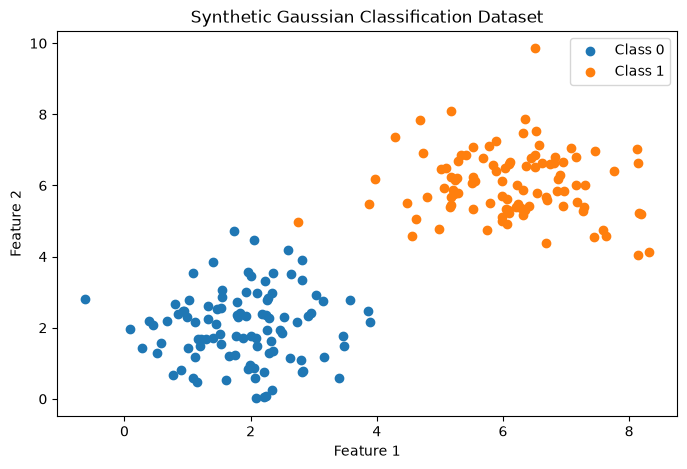

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Class 0"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Class 1"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Gaussian Classification Dataset")
plt.legend()
plt.show()

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


In [29]:
scratch_model = GaussianNB()

scratch_model.fit(X_train, y_train)

y_pred = scratch_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Scratch Gaussian NB Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Scratch Gaussian NB Accuracy: 1.0

Confusion Matrix:
[[20  0]
 [ 0 20]]


In [30]:
probabilities = scratch_model.predict_proba(X_test[:5])

for i, probability in enumerate(probabilities):
    print(
        f"Observation {i + 1}: "
        f"Class 0 = {probability[0]:.4f}, "
        f"Class 1 = {probability[1]:.4f}"
    )

Observation 1: Class 0 = 1.0000, Class 1 = 0.0000
Observation 2: Class 0 = 0.0000, Class 1 = 1.0000
Observation 3: Class 0 = 0.0000, Class 1 = 1.0000
Observation 4: Class 0 = 0.0000, Class 1 = 1.0000
Observation 5: Class 0 = 1.0000, Class 1 = 0.0000


In [31]:
from sklearn.naive_bayes import GaussianNB as SklearnGaussianNB

sklearn_model = SklearnGaussianNB()

sklearn_model.fit(X_train, y_train)

sklearn_predictions = sklearn_model.predict(X_test)

sklearn_accuracy = accuracy_score(
    y_test,
    sklearn_predictions
)

print("Scratch accuracy:", accuracy)
print("Scikit-learn accuracy:", sklearn_accuracy)

Scratch accuracy: 1.0
Scikit-learn accuracy: 1.0


In [32]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Scratch Prediction": y_pred,
    "Sklearn Prediction": sklearn_predictions
})

comparison["Scratch Correct"] = (
    comparison["Actual"] == comparison["Scratch Prediction"]
)

comparison["Sklearn Correct"] = (
    comparison["Actual"] == comparison["Sklearn Prediction"]
)

comparison.head(10)

,Actual,Scratch Prediction,Sklearn Prediction,Scratch Correct,Sklearn Correct
0,0,0,0,True,True
1,1,1,1,True,True
2,1,1,1,True,True
3,1,1,1,True,True
4,0,0,0,True,True
5,1,1,1,True,True
6,0,0,0,True,True
7,1,1,1,True,True
8,1,1,1,True,True
9,0,0,0,True,True


## IRIS REAL WORLD DATASET

In [33]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
class_names = iris.target_names

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(feature_names)

print("\nClasses:")
print(class_names)

Dataset shape: (150, 4)
Target shape: (150,)

Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Classes:
['setosa' 'versicolor' 'virginica']


In [34]:
df = pd.DataFrame(X, columns=feature_names)

df["species"] = [
    class_names[label] for label in y
]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [35]:
print("Dataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["species"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
None

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate rows: 1

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


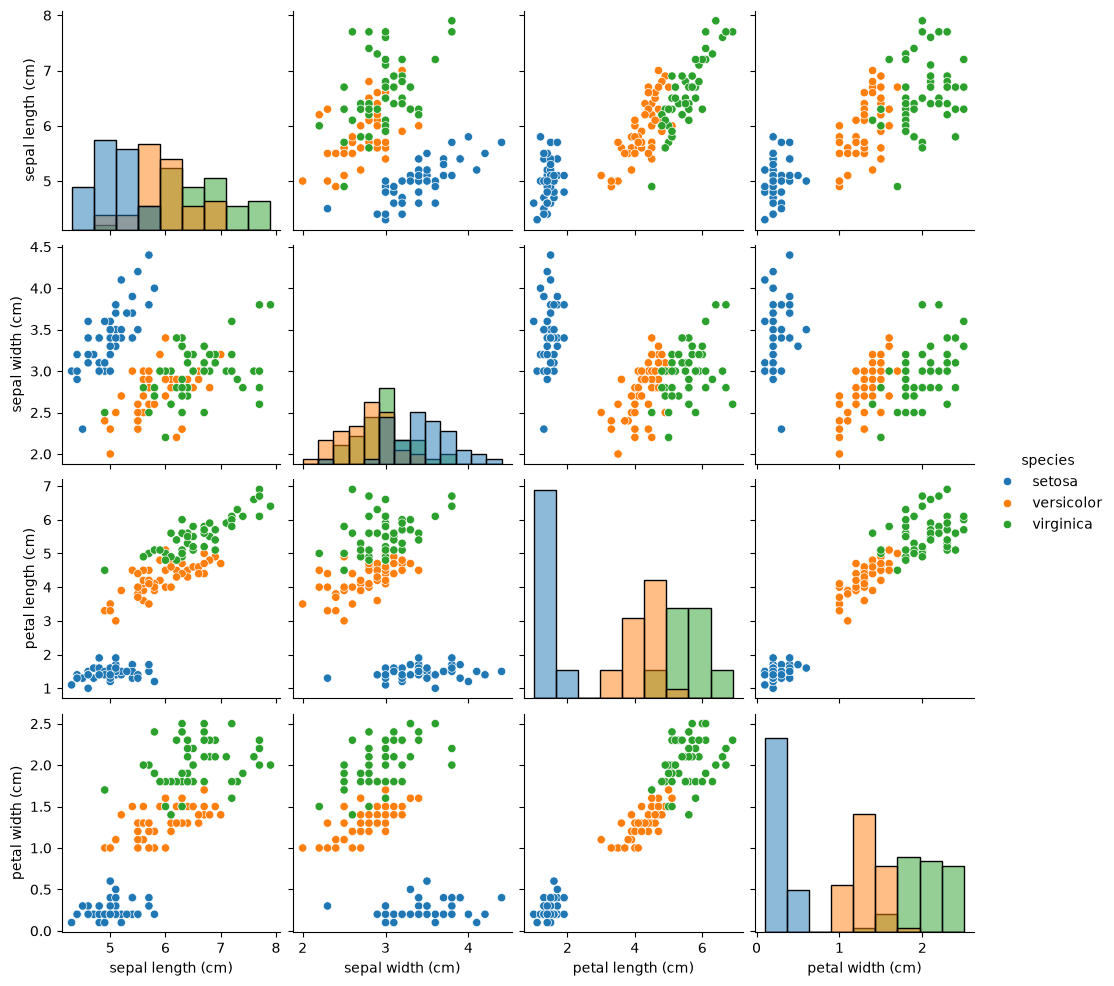

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training shape: (120, 4)
Testing shape: (30, 4)

Training class distribution:
0    40
1    40
2    40
Name: count, dtype: int64

Testing class distribution:
0    10
1    10
2    10
Name: count, dtype: int64


In [38]:
scratch_model = GaussianNB()

scratch_model.fit(X_train, y_train)

y_pred_scratch = scratch_model.predict(X_test)

print("Scratch Gaussian NB Accuracy:",
      accuracy_score(y_test, y_pred_scratch))

Scratch Gaussian NB Accuracy: 0.9666666666666667


In [39]:
comparison = pd.DataFrame({
    "Actual": [class_names[i] for i in y_test],
    "Predicted": [class_names[i] for i in y_pred_scratch]
})

comparison["Correct"] = (
    comparison["Actual"] == comparison["Predicted"]
)

comparison

,Actual,Predicted,Correct
0,setosa,setosa,True
1,virginica,virginica,True
2,versicolor,versicolor,True
3,versicolor,versicolor,True
4,setosa,setosa,True
5,versicolor,versicolor,True
6,setosa,setosa,True
7,setosa,setosa,True
8,virginica,virginica,True
9,versicolor,versicolor,True


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



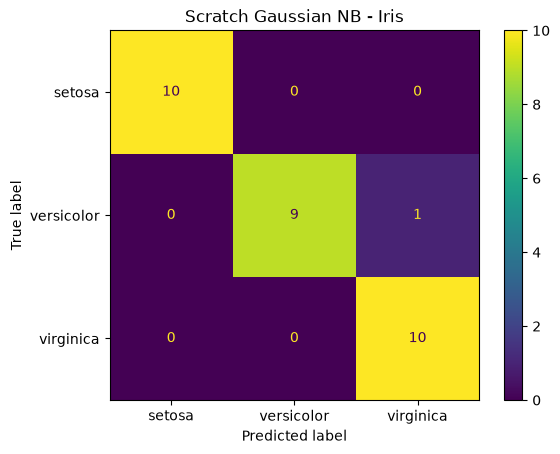

In [40]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(classification_report(
    y_test,
    y_pred_scratch,
    target_names=class_names
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_scratch,
    display_labels=class_names
)

plt.title("Scratch Gaussian NB - Iris")
plt.show()

In [41]:
sklearn_model = SklearnGaussianNB()

sklearn_model.fit(X_train, y_train)

y_pred_sklearn = sklearn_model.predict(X_test)

print(
    "Scratch accuracy:",
    accuracy_score(y_test, y_pred_scratch)
)

print(
    "Sklearn accuracy:",
    accuracy_score(y_test, y_pred_sklearn)
)

print(
    "Predictions identical:",
    np.array_equal(y_pred_scratch, y_pred_sklearn)
)

Scratch accuracy: 0.9666666666666667
Sklearn accuracy: 0.9666666666666667
Predictions identical: True


In [42]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    SklearnGaussianNB(),
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation scores:", cv_scores)
print("Mean accuracy:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation scores: [0.95833333 0.95833333 0.95833333 0.95833333 0.91666667]
Mean accuracy: 0.95
Standard deviation: 0.016666666666666698


In [43]:
new_flowers = np.array([
    [5.1, 3.5, 1.4, 0.2],
    [6.0, 2.9, 4.5, 1.5],
    [6.7, 3.0, 5.2, 2.3]
])

predictions = scratch_model.predict(new_flowers)

probabilities = scratch_model.predict_proba(new_flowers)

for i, prediction in enumerate(predictions):
    print(f"\nFlower {i + 1}")
    print("Predicted species:", class_names[prediction])

    for class_index, class_name in enumerate(class_names):
        print(
            f"{class_name}: "
            f"{probabilities[i][class_index]:.4f}"
        )


Flower 1
Predicted species: setosa
setosa: 1.0000
versicolor: 0.0000
virginica: 0.0000

Flower 2
Predicted species: versicolor
setosa: 0.0000
versicolor: 0.9906
virginica: 0.0094

Flower 3
Predicted species: virginica
setosa: 0.0000
versicolor: 0.0000
virginica: 1.0000
